In [11]:

import sys
from pathlib import Path

# Find the project root automatically
current_dir = Path.cwd().resolve()

project_root = next(
    (
        path for path in (current_dir, *current_dir.parents)
        if (path / "src" / "utils.py").is_file()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        f"Project root not found from {current_dir}. "
        "Open the MMM project folder in VS Code."
    )

# Add project root to Python's import path
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)
print("Project path configured successfully!")


Project root: D:\Internship Tasks\Group Task - Marketing Mix Modelling (MMM) & Budget Optimisation\mmm-budget-optimization
Project path configured successfully!


In [12]:

import pandas as pd
import numpy as np

from src.utils import DATA_PROCESSED, load_params

# Load the existing project configuration
params = load_params()

# Load the previous subgroup's feature-engineered dataset
data_path = DATA_PROCESSED / "feature_engineered_marketing_mix_data.csv"

df = pd.read_csv(data_path, parse_dates=["month"])

# Sort chronologically (important for Adstock)
df = df.sort_values("month").reset_index(drop=True)

print("Dataset shape:", df.shape)
print("First month:", df["month"].min())
print("Last month:", df["month"].max())

display(df.head())


Dataset shape: (36, 44)
First month: 2023-01-01 00:00:00
Last month: 2025-12-01 00:00:00


,month,country,brand_category,region_scope,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,...,revenue_per_unit,revenue_per_conversion,roas,cost_per_conversion,lag_1_total_spend,lag_2_total_spend,rolling_3_month_spend,marketing_pressure,competitive_advantage,promotion_impact
0,2023-01-01,Sri Lanka,FMCG - Packaged Foods,National,4274762,3890003,2467793,1836858,1700676,1813444,...,558.637776,57.943069,4.386643,13.208977,0.0,0.0,0.000000e+00,12469416,50.4,7.8516
1,2023-02-01,Sri Lanka,FMCG - Packaged Foods,National,4023574,5062635,2962576,2254198,1922384,2941194,...,633.780115,110.710778,3.839737,28.832909,15983536.0,0.0,0.000000e+00,14302983,49.0,9.0912
2,2023-03-01,Sri Lanka,FMCG - Packaged Foods,National,5359091,3746337,4080535,2363737,1720670,2063917,...,562.908050,223.483184,4.399608,50.796156,19166561.0,15983536.0,1.816146e+07,15549700,54.1,6.8300
3,2023-04-01,Sri Lanka,FMCG - Packaged Foods,National,5102550,3690115,3390558,2595121,1217450,3091430,...,533.883913,81.452943,5.242138,15.538116,19334287.0,19166561.0,1.919602e+07,14778344,68.8,25.6088
4,2023-05-01,Sri Lanka,FMCG - Packaged Foods,National,4972723,5333813,3240078,2343364,1568285,3525300,...,461.062423,137.662905,3.693476,37.271909,19087224.0,19334287.0,1.980169e+07,15889978,47.0,2.1450


In [13]:

# Read channel names and target from existing config
channels = params["channels"]
target = params["target"]

print("Marketing Channels:")
for i, channel in enumerate(channels, start=1):
    print(f"{i}. {channel}")

print("\nTarget variable:", target)

# Display advertising spend and sales
display(df[["month"] + channels + [target]].head())


Marketing Channels:
1. tv_spend_lkr
2. facebook_instagram_spend_lkr
3. google_search_spend_lkr
4. youtube_spend_lkr
5. radio_spend_lkr
6. outdoor_spend_lkr

Target variable: sales_revenue_lkr


,month,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,sales_revenue_lkr
0,2023-01-01,4274762,3890003,2467793,1836858,1700676,1813444,7.011407e+07
1,2023-02-01,4023574,5062635,2962576,2254198,1922384,2941194,7.359455e+07
2,2023-03-01,5359091,3746337,4080535,2363737,1720670,2063917,8.506329e+07
3,2023-04-01,5102550,3690115,3390558,2595121,1217450,3091430,1.000579e+08
4,2023-05-01,4972723,5333813,3240078,2343364,1568285,3525300,7.750229e+07


In [14]:

# Basic validation checks
print("Missing values:", df.isnull().sum().sum())
print("Duplicate months:", df["month"].duplicated().sum())

# Check for missing months
expected_months = pd.date_range(
    start=df["month"].min(),
    end=df["month"].max(),
    freq="MS"
)

missing_months = expected_months.difference(df["month"])
print("Missing months:", len(missing_months))

# Check for negative advertising spend
negative_spend = (df[channels] < 0).sum().sum()
print("Negative spend values:", negative_spend)

# Check our main required columns
required_columns = ["month"] + channels + [target]
print(
    "Required columns available:",
    all(col in df.columns for col in required_columns)
)


Missing values: 0
Duplicate months: 0
Missing months: 0
Negative spend values: 0
Required columns available: True


In [15]:

from src.transforms import geometric_adstock

# Small example to test the existing function
spend = np.array([100, 0, 0])

result = geometric_adstock(spend, decay=0.4)

print("Original spend:", spend)
print("Adstock result:", result)


Original spend: [100   0   0]
Adstock result: [100.  40.  16.]


## Step 3: Geometric Adstock Transformation

In [16]:

import importlib
import src.transforms as transforms

# Reload the updated Python module
importlib.reload(transforms)

# Update the notebook's function reference
geometric_adstock = transforms.geometric_adstock

print("Updated Adstock function loaded successfully!")


Updated Adstock function loaded successfully!


In [18]:

from src.transforms import geometric_adstock

# Test 1: Advertising carryover
test_spend = np.array([100, 0, 0, 0], dtype=float)

test_result = geometric_adstock(test_spend, decay=0.4)

expected = np.array([100, 40, 16, 6.4])

np.testing.assert_allclose(test_result, expected)

# Test 2: Zero decay means no carryover
zero_decay = geometric_adstock(test_spend, decay=0.0)

np.testing.assert_allclose(zero_decay, test_spend)

# Test 3: Invalid decay must be rejected
try:
    geometric_adstock(test_spend, decay=1.5)
except ValueError:
    pass
else:
    raise AssertionError("Invalid decay was not rejected.")

print("All Adstock tests passed!")
print("Test result:", test_result)


All Adstock tests passed!
Test result: [100.   40.   16.    6.4]


In [19]:

# Get channel names and decay parameters from config
channels = params["channels"]
decay_rates = params["adstock_decay"]

# Keep transformed features separate from source dataset
adstock_df = df[["month"]].copy()

# Apply geometric adstock for all six channels
for channel in channels:

    decay = decay_rates[channel]

    # Example: tv_spend_lkr -> tv_adstock_lkr
    output_name = (
        channel.removesuffix("_spend_lkr") + "_adstock_lkr"
    )

    adstock_df[output_name] = geometric_adstock(
        df[channel].to_numpy(dtype=float),
        decay=decay
    )

    print(f"{channel}: decay = {decay}")

print("\nAdstock transformations completed!")
print("Output shape:", adstock_df.shape)

display(adstock_df.head())


tv_spend_lkr: decay = 0.4
facebook_instagram_spend_lkr: decay = 0.2
google_search_spend_lkr: decay = 0.1
youtube_spend_lkr: decay = 0.3
radio_spend_lkr: decay = 0.2
outdoor_spend_lkr: decay = 0.3

Adstock transformations completed!
Output shape: (36, 7)


,month,tv_adstock_lkr,facebook_instagram_adstock_lkr,google_search_adstock_lkr,youtube_adstock_lkr,radio_adstock_lkr,outdoor_adstock_lkr
0,2023-01-01,4.274762e+06,3.890003e+06,2.467793e+06,1.836858e+06,1.700676e+06,1.813444e+06
1,2023-02-01,5.733479e+06,5.840636e+06,3.209355e+06,2.805255e+06,2.262519e+06,3.485227e+06
2,2023-03-01,7.652483e+06,4.914464e+06,4.401471e+06,3.205314e+06,2.173174e+06,3.109485e+06
3,2023-04-01,8.163543e+06,4.673008e+06,3.830705e+06,3.556715e+06,1.652085e+06,4.024276e+06
4,2023-05-01,8.238140e+06,6.268415e+06,3.623149e+06,3.410379e+06,1.898702e+06,4.732583e+06


In [20]:

assert len(adstock_df) == len(df)
assert adstock_df.shape[1] == 7

for channel in channels:
    name = channel.removesuffix("_spend_lkr") + "_adstock_lkr"

    raw_spend = df[channel].to_numpy(dtype=float)
    transformed = adstock_df[name].to_numpy()

    # No missing or infinite outputs
    assert np.isfinite(transformed).all()

    # Nonnegative spend with nonnegative decay
    assert np.all(transformed >= raw_spend - 1e-8)

    # First month assumes zero earlier carryover
    np.testing.assert_allclose(
        transformed[0], raw_spend[0]
    )

# Known value check using actual January/February TV spend
np.testing.assert_allclose(
    adstock_df.loc[1, "tv_adstock_lkr"],
    5733478.8
)

print("All six Adstock channels validated successfully!")


All six Adstock channels validated successfully!


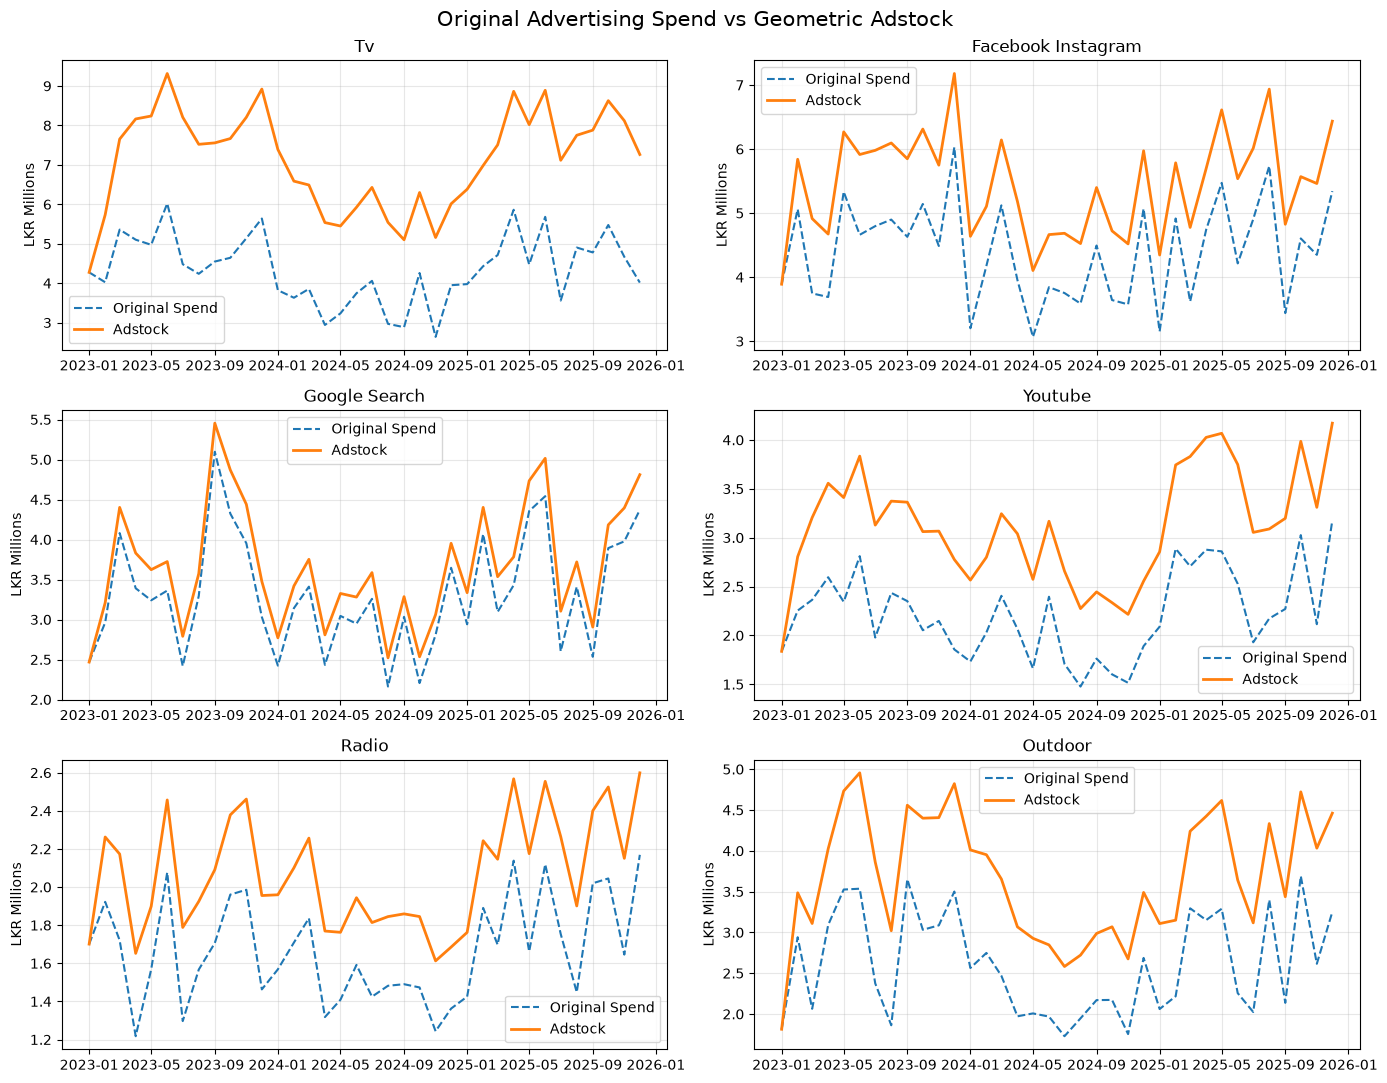

In [21]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(14, 11))
axes = axes.flatten()

for i, channel in enumerate(channels):

    ax = axes[i]

    adstock_col = (
        channel.removesuffix("_spend_lkr") + "_adstock_lkr"
    )

    # Convert LKR to millions for readability
    original = df[channel] / 1_000_000
    transformed = adstock_df[adstock_col] / 1_000_000

    ax.plot(
        df["month"],
        original,
        label="Original Spend",
        linestyle="--"
    )

    ax.plot(
        df["month"],
        transformed,
        label="Adstock",
        linewidth=2
    )

    ax.set_title(channel.replace("_spend_lkr", "").replace("_", " ").title())
    ax.set_ylabel("LKR Millions")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Original Advertising Spend vs Geometric Adstock",
    fontsize=15
)

plt.tight_layout()
plt.show()
